# Notebook 06: Entrenamiento, Loss, Backpropagation y Optimización

**Objetivo:** Clonar el repositorio, importar el modelo desde `src/model.py`, cargar los datos escalados generados en `02_quality.ipynb`, configurar la función de pérdida Binary Cross-Entropy (BCE) y el optimizador Adam, y ejecutar el entrenamiento registrando la curva de pérdida en entrenamiento y validación (Secciones 8, 9, 10 y 11 de la plantilla).

In [1]:
import os
import sys
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Clonar el repositorio para acceder a la carpeta src (si no existe)
if not os.path.exists('redes-neuronales-riesgo-crediticio'):
    !git clone https://github.com/JuanCardona2203/redes-neuronales-riesgo-crediticio.git

for repo_path in ['/content/redes-neuronales-riesgo-crediticio', '..']:
    if repo_path not in sys.path:
        sys.path.append(repo_path)

from src.model import CreditRiskMLP

In [2]:
# Semilla fija para reproducibilidad (Sección 10)
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Carga de los datos escalados generados en 02_quality.ipynb
X_train = pd.read_csv('data/processed/X_train_scaled.csv').values
y_train = pd.read_csv('data/processed/y_train.csv').values.ravel()

# División interna Train/Validación (80/20) manteniendo proporción de clases
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=SEED, stratify=y_train
)

# Conversión a tensores de PyTorch
X_tr_t = torch.tensor(X_tr, dtype=torch.float32)
y_tr_t = torch.tensor(y_tr, dtype=torch.float32).unsqueeze(1)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32).unsqueeze(1)

print(f"Entrenamiento: {X_tr_t.shape[0]} muestras | Validación: {X_val_t.shape[0]} muestras")

Entrenamiento: 20848 muestras | Validación: 5212 muestras


In [3]:
# Instanciar modelo, función de pérdida y optimizador (Secciones 8 y 10)
model = CreditRiskMLP(input_dim=6)
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001, betas=(0.9, 0.999))

# Hiperparámetros (Sección 10)
epochs = 50
batch_size = 32

train_ds = torch.utils.data.TensorDataset(X_tr_t, y_tr_t)
train_loader = torch.utils.data.DataLoader(train_ds, batch_size=batch_size, shuffle=True)

print(model)

CreditRiskMLP(
  (hidden1): Linear(in_features=6, out_features=16, bias=True)
  (relu1): ReLU()
  (hidden2): Linear(in_features=16, out_features=8, bias=True)
  (relu2): ReLU()
  (output): Linear(in_features=8, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)


In [4]:
# Ciclo de entrenamiento con registro de pérdida (Secciones 9 y 11)
history = {'train_loss': [], 'val_loss': []}

print("--- Iniciando Ciclo de Entrenamiento ---")
for epoch in range(epochs):
    model.train()
    running = 0.0
    for xb, yb in train_loader:
        optimizer.zero_grad()       # Limpiar gradientes anteriores
        outputs = model(xb)         # Forward Pass
        loss = criterion(outputs, yb)
        loss.backward()             # Backpropagation
        optimizer.step()            # Actualización de pesos (Adam)
        running += loss.item() * xb.size(0)
    train_loss = running / len(train_ds)

    model.eval()
    with torch.no_grad():
        val_loss = criterion(model(X_val_t), y_val_t).item()

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)

    if (epoch + 1) % 5 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

print("Entrenamiento concluido con éxito.")

--- Iniciando Ciclo de Entrenamiento ---


Epoch [5/50], Train Loss: 0.3912, Val Loss: 0.3856


Epoch [10/50], Train Loss: 0.3849, Val Loss: 0.3804


Epoch [15/50], Train Loss: 0.3792, Val Loss: 0.3738


Epoch [20/50], Train Loss: 0.3739, Val Loss: 0.3674


Epoch [25/50], Train Loss: 0.3713, Val Loss: 0.3686


Epoch [30/50], Train Loss: 0.3704, Val Loss: 0.3645


Epoch [35/50], Train Loss: 0.3691, Val Loss: 0.3644


Epoch [40/50], Train Loss: 0.3682, Val Loss: 0.3632


Epoch [45/50], Train Loss: 0.3649, Val Loss: 0.3605


Epoch [50/50], Train Loss: 0.3635, Val Loss: 0.3593
Entrenamiento concluido con éxito.


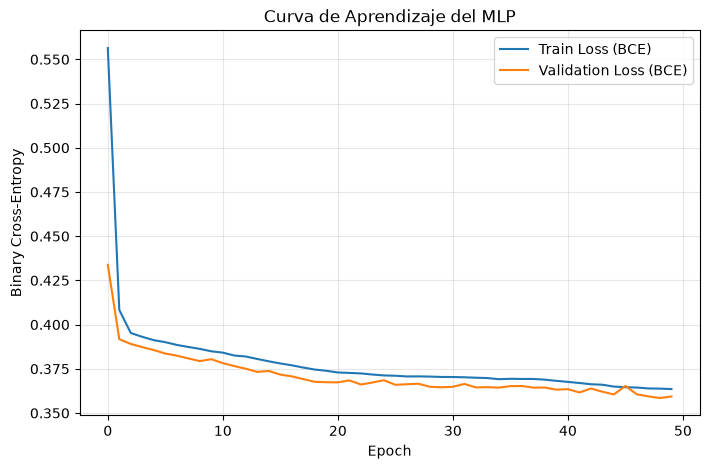

In [5]:
# Curva de aprendizaje: la pérdida debe descender (Sección 11)
plt.figure(figsize=(8, 5))
plt.plot(history['train_loss'], label='Train Loss (BCE)')
plt.plot(history['val_loss'], label='Validation Loss (BCE)')
plt.xlabel('Epoch')
plt.ylabel('Binary Cross-Entropy')
plt.title('Curva de Aprendizaje del MLP')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [6]:
# Guardado del modelo entrenado (Sección 11)
os.makedirs('models', exist_ok=True)
torch.save(model.state_dict(), 'models/mlp_credit_risk.pt')
print("Modelo guardado en 'models/mlp_credit_risk.pt'.")

Modelo guardado en 'models/mlp_credit_risk.pt'.
